# Neuron

Validation of `snnrl.neuron`

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from snnrl.neuron import make_params, run, threshold, init_state

## 1. Voltage traces

One LIF and one ALIF neuron under the same constant step current.

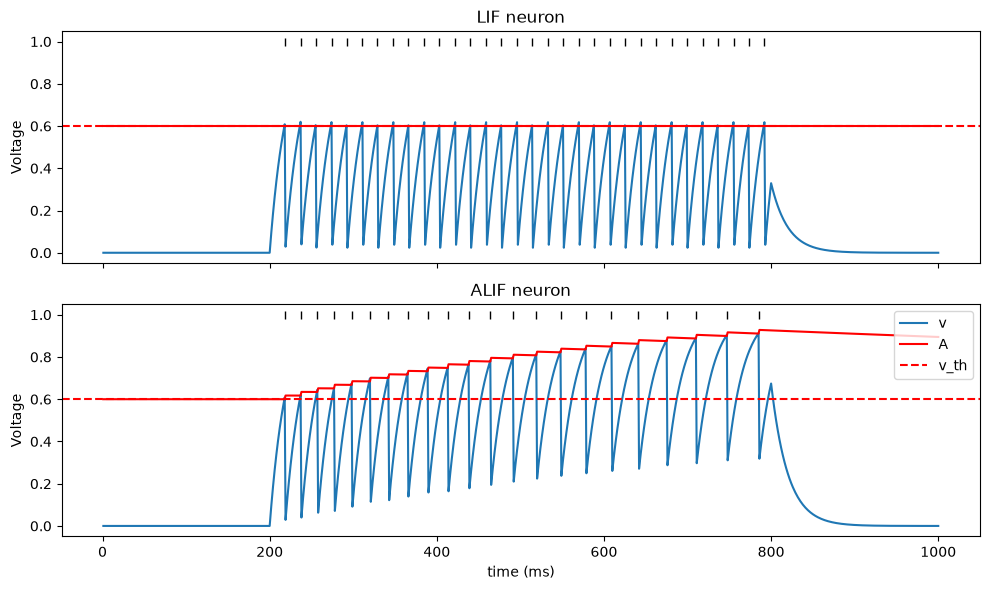

In [2]:
T = 1000 # ms

params = make_params(n_lif=1, n_alif=1)
current = jnp.zeros((T, 2))
current = current.at[200:800].set(0.05)
_, history = run(current, params)

t = jnp.arange(1, T + 1)
A = threshold(history.a, params) # (T, 2)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

def plot_voltage(t, history, A, neuron_id, ax):
    ax.plot(t, history.v[:, neuron_id], label="v")
    ax.plot(t, A[:, neuron_id], color='red', label="A")
    spike_times = t[history.z[:, neuron_id] > 0]
    ax.plot(spike_times, jnp.ones(spike_times.shape), "|", color="k", ms=6)
    ax.set_ylabel(f"Voltage")

# LIF neuron
plot_voltage(t, history, A, neuron_id=0, ax=axes[0])
axes[0].axhline(params.v_th, color='red', linestyle='--', label="v_th")
axes[0].set_title('LIF neuron')

# ALIF neuron
plot_voltage(t, history, A, neuron_id=1, ax=axes[1])
axes[1].axhline(params.v_th, color='red', linestyle='--', label="v_th")
axes[1].set_title('ALIF neuron')
axes[1].legend(loc="upper right")
axes[1].set_xlabel("time (ms)")

plt.tight_layout()

Plot pseudo-derivative

Text(0.5, 1.0, 'ALIF neuron')

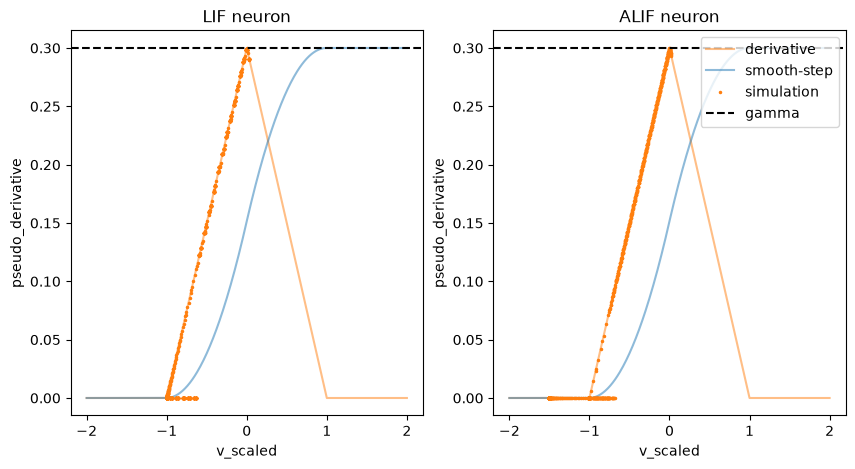

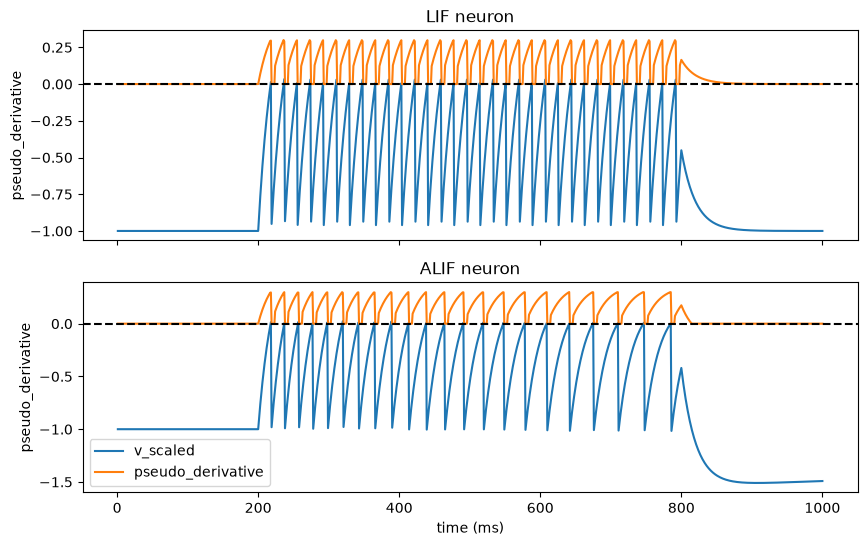

In [3]:
v_scaled = (history.v - A) / params.v_th
pseudo_derivative = params.gamma * jnp.maximum(0.0, 1.0 - jnp.abs(v_scaled))
# zero out the pseudo-derivative during refractory period
pseudo_derivative *= (history.r == 0) 
x = jnp.linspace(-2, 2, 401)
triangle = params.gamma * jnp.maximum(0.0, 1.0 - jnp.abs(x))
S = jnp.cumsum(triangle) * (x[1] - x[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True)

axes[0].plot(x, triangle, color='C1', alpha=0.5, label="derivative")
axes[0].plot(x, S, color='C0', alpha=0.5, label="smooth-step")
axes[0].plot(v_scaled[:, 0], pseudo_derivative[:, 0], ".", color='C1', ms=3, label="simulation")
axes[0].axhline(params.gamma, color='k', linestyle='--', label="gamma")
axes[0].set_xlabel("v_scaled")
axes[0].set_ylabel("pseudo_derivative")
axes[0].set_title('LIF neuron')

axes[1].plot(x, triangle, color='C1', alpha=0.5, label="derivative")
axes[1].plot(x, S, color='C0', alpha=0.5, label="smooth-step")
axes[1].plot(v_scaled[:, 1], pseudo_derivative[:, 1], ".", color='C1', ms=3, label="simulation")
axes[1].axhline(params.gamma, color='k', linestyle='--', label="gamma")
axes[1].set_xlabel("v_scaled")
axes[1].set_ylabel("pseudo_derivative")
axes[1].legend(loc="upper right")
axes[1].set_title('ALIF neuron')


fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(t, v_scaled[:, 0], label="v_scaled")
axes[0].plot(t, pseudo_derivative[:, 0], label="pseudo_derivative")
axes[0].axhline(0, color='k', linestyle='--')
axes[0].set_ylabel("pseudo_derivative")
axes[0].set_title('LIF neuron')

axes[1].plot(t, v_scaled[:, 1], label="v_scaled")
axes[1].plot(t, pseudo_derivative[:, 1], label="pseudo_derivative")
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set_xlabel("time (ms)")
axes[1].set_ylabel("pseudo_derivative")
axes[1].legend(loc="lower left")
axes[1].set_title('ALIF neuron')

Calculate spike counts and inter-spike intervals (ISI)

In [4]:
lif_spikes = int(history.z[:, 0].sum())
alif_spikes = int(history.z[:, 1].sum())
lif_isi = jnp.diff(t[history.z[:, 0] > 0])
alif_isi = jnp.diff(t[history.z[:, 1] > 0])

print(f"LIF: {lif_spikes} spikes, first ISI {int(lif_isi[0])} ms, last ISI {int(lif_isi[-1])} ms")
print(f"ALIF: {alif_spikes} spikes, first ISI {int(alif_isi[0])} ms, last ISI {int(alif_isi[-1])} ms")

LIF: 32 spikes, first ISI 19 ms, last ISI 19 ms
ALIF: 22 spikes, first ISI 19 ms, last ISI 38 ms


Plot states (normalized)

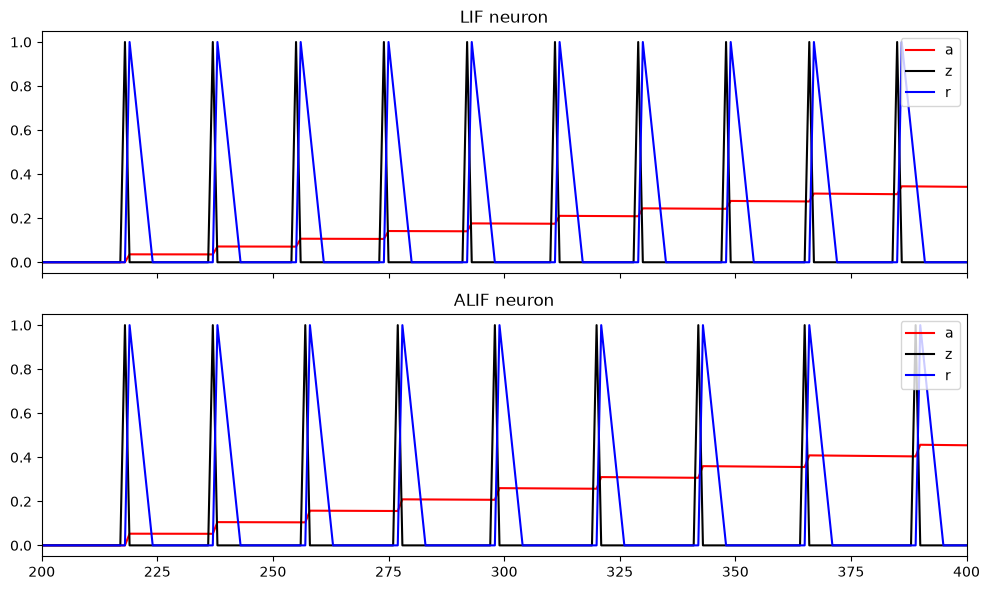

In [5]:
a = history.a # threshold adaptation variable
z = history.z # spikes (0 or 1)
r = history.r # remaining refractory steps (countdown)

def normalize(x):
    return x / x.max()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# LIF neuron
axes[0].plot(t, normalize(a[:, 0]), color='r', label="a")
axes[0].plot(t, normalize(z[:, 0]), color='k', label="z")
axes[0].plot(t, normalize(r[:, 0]), color='b', label="r")
axes[0].set_xlim(200, 400)
axes[0].legend(loc="upper right")
axes[0].set_title('LIF neuron')

# ALIF neuron
axes[1].plot(t, normalize(a[:, 1]), color='r', label="a")
axes[1].plot(t, normalize(z[:, 1]), color='k', label="z")
axes[1].plot(t, normalize(r[:, 1]), color='b', label="r")
axes[1].legend(loc="upper right")
axes[1].set_title('ALIF neuron')
plt.tight_layout()

Run the simulation in chunks and validate against the one-pass run

Validation: True True True True


Text(0.5, 0, 'time (ms)')

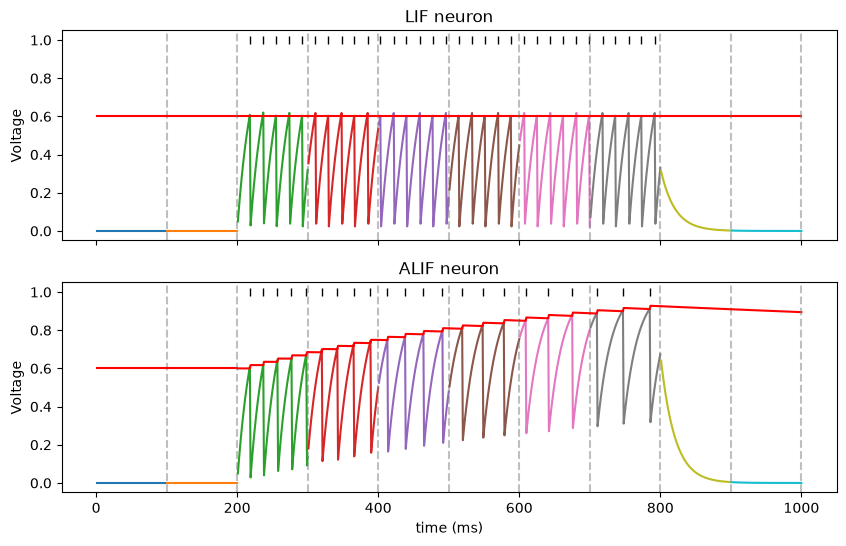

In [6]:
T = 1000 # ms

params = make_params(n_lif=1, n_alif=1)
current = jnp.zeros((T, 2))
current = current.at[200:800].set(0.05)

# Run the simulation in chunks
full_history = []
current_chunks = [current[i * 100:(i + 1) * 100] for i in range(10)]
state = init_state(2)
for current_chunk in current_chunks:
    state, history = run(current_chunk, params, state)
    full_history.append(history)

# Validate against the one-pass run
_, one_pass_history = run(current, params)
concatenated_history = jax.tree_util.tree_map(
    lambda *x: jnp.concatenate(x, axis=0), 
    *full_history
)
print(
    "Validation:", 
    jnp.allclose(concatenated_history.v, one_pass_history.v), 
    jnp.allclose(concatenated_history.a, one_pass_history.a), 
    jnp.array_equal(concatenated_history.z, one_pass_history.z), 
    jnp.array_equal(concatenated_history.r, one_pass_history.r)
)


fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# LIF neuron
for i, history in enumerate(full_history):
    t = jnp.arange(i * 100 + 1, (i + 1) * 100 + 1)
    A = threshold(history.a, params) # (T, 2)
    plot_voltage(t, history, A, neuron_id=0, ax=axes[0])
    axes[0].axvline(t[-1], color='gray', linestyle='--', alpha=0.5)
axes[0].set_title('LIF neuron')

# ALIF neuron
for i, history in enumerate(full_history):
    t = jnp.arange(i * 100 + 1, (i + 1) * 100 + 1)
    A = threshold(history.a, params) # (T, 2)
    plot_voltage(t, history, A, neuron_id=1, ax=axes[1])
    axes[1].axvline(t[-1], color='gray', linestyle='--', alpha=0.5)
axes[1].set_title('ALIF neuron')
axes[1].set_xlabel("time (ms)")

## 2. F-I curves

50 LIF and 50 ALIF neurons, each pair driven by a different constant current for 3 s.

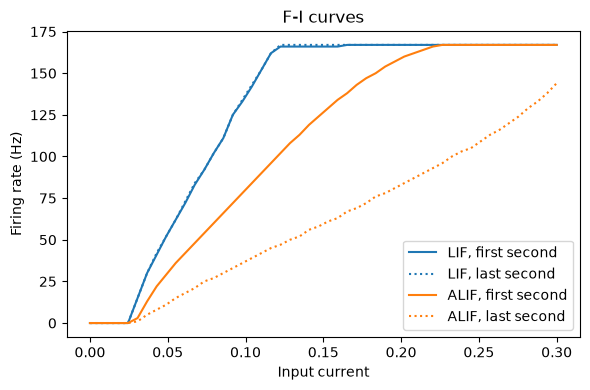

In [7]:
N = 50 # number of neurons
T = 3000 # ms

params = make_params(n_lif=N, n_alif=N)
currents = jnp.linspace(0.0, 0.3, N)
pairwise_currents = jnp.tile(currents, 2)[None, :].repeat(T, axis=0)

_, history = run(pairwise_currents, params)

rate_first = history.z[:1000].mean(0) * 1000 # Hz, first second
rate_last = history.z[-1000:].mean(0) * 1000 # Hz, last second

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(currents, rate_first[:N], "C0-", label="LIF, first second")
ax.plot(currents, rate_last[:N], "C0:", label="LIF, last second")
ax.plot(currents, rate_first[N:], "C1-", label="ALIF, first second")
ax.plot(currents, rate_last[N:], "C1:", label="ALIF, last second")
ax.set_xlabel("Input current")
ax.set_ylabel("Firing rate (Hz)")
ax.set_title("F-I curves")
ax.legend()
plt.tight_layout()